# Notebook 8 (v2) — full-brain release: privacy–utility frontier

Implements `SPEC_NB8.md` (v2) and the 2026-10-23 review actions. Settled mechanism: `z = Σ aₘVₘ`,
hard **per-eigenmode-max** bar `bₘ = maxᵢ|Dᵢ·Vₘ|`, all modes noised (`k_noise=r`), sampled by the
rejection-free **direct sampler**. Attack: known-background **projection** membership advantage,
whole-brain. Engine: `release_noise.py` (Tier-3); frozen `mode_eigen_mech.py`, `privacy_harness.py`,
`inference_eval.py` untouched. **Empirical privacy only — no formal ε.**

**Targets** (all three evaluated): `worst` (real subject least covered by the L2 bar — the
discriminating case), `ksigma` (synthetic mean+2σ outlier), `istar` (the subject the L2 bar is built
on — a covered control). **Advantage** = `TPR − FPR` (chance = 0; see §1). **Acceptable** = upper 95 %
CI of advantage ≤ **ε = 0.1**.

## 0 · Setup, frozen check, configuration

In [1]:
# CAP BLAS THREADS BEFORE importing numpy — else every tiny per-patch SVD spawns ~cpu_count threads.
import os
for _v in ("OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS","VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"
import sys, hashlib, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
for c in [".", "work", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(c, "privacy_harness.py")): sys.path.insert(0, c); break
import privacy_harness as ph, mode_eigen_mech as me, tiling as T
import full_release_attacks as fra, release_noise as R
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
FROZEN = {"privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
          "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018"}
for f, h in FROZEN.items():
    p = next((os.path.join(c, f) for c in [".", "work", os.path.expanduser("~/harness")]
              if os.path.exists(os.path.join(c, f))), None)
    if p: print(f"  {f}: {'OK' if hashlib.sha256(open(p,'rb').read()).hexdigest()==h else 'CHANGED!'}")

  privacy_harness.py: OK
  inference_eval.py: OK


In [2]:
USE_OASIS = True                 # False -> portable phantom + reduced grid (end-to-end validation)
BLEND     = "pou_energy"
EPS       = 0.10                 # acceptable-advantage criterion: upper 95% CI of advantage <= EPS
from joblib import Parallel, delayed
SEED = 0
CKPT_DIR = os.path.abspath("nb8_ckpt")      # §3 frontier is cached here; delete to force a recompute

if USE_OASIS:
    N          = 40
    PATCHES    = {"3x3x3": (3,3,3), "5x5x5": (5,5,5), "7x7x7": (7,7,7), "single": "single"}
    OVERLAPS   = [0.0, 0.25, 0.5]
    STATS      = ["mean", "median", "variance"]
    TARGETS    = ["worst", "ksigma", "istar"]
    SCALES     = [1, 2, 3, 5, 8, 12]
    KCHECKS    = [8, 16, 26, None]          # None = r (full-rank policing)
    N_SWEEP    = [20, 40, 60, 80, 100]
    REP_PATCH  = "5x5x5"; REP_SCALE = 5; KC_SCALES = [1, 12]
    ISO_SIZES  = [(3,3,3), (5,5,5), (7,7,7)]
    N_TRIALS, N_REL, N_MC = 4000, 50, 200
else:
    N          = 30
    PATCHES    = {"5x5x5": (5,5,5), "single": "single"}
    OVERLAPS   = [0.5]
    STATS      = ["mean", "variance"]
    TARGETS    = ["worst", "ksigma", "istar"]
    SCALES     = [1, 4, 10]
    KCHECKS    = [8, None]
    N_SWEEP    = [15, 20, 30]
    REP_PATCH  = "5x5x5"; REP_SCALE = 4; KC_SCALES = [1, 10]
    ISO_SIZES  = [(5,5,5)]
    N_TRIALS, N_REL, N_MC = 1500, 20, 80

N_JOBS = 20
PKW    = dict(n_jobs=N_JOBS, verbose=10, inner_max_num_threads=1)
REP_PATCH_PS = PATCHES[REP_PATCH]
PCOL = {"3x3x3":"#4575b4","5x5x5":"#91bfdb","7x7x7":"#fc8d59","single":"#d73027"}
TCOL = {"worst":"#d73027","ksigma":"#1f78b4","istar":"#33a02c"}
print(f"patches={list(PATCHES)} overlaps={OVERLAPS} stats={STATS} targets={TARGETS}")
print(f"scales={SCALES} | N={N} n_trials={N_TRIALS} n_rel={N_REL} n_mc={N_MC} n_jobs={N_JOBS} eps={EPS}")

patches=['3x3x3', '5x5x5', '7x7x7', 'single'] overlaps=[0.0, 0.25, 0.5] stats=['mean', 'median', 'variance'] targets=['worst', 'ksigma', 'istar']
scales=[1, 2, 3, 5, 8, 12] | N=40 n_trials=4000 n_rel=50 n_mc=200 n_jobs=20 eps=0.1


In [3]:
# substrate: OASIS gray-matter maps (whole volume) or a portable phantom
def gm_mask(volumes):
    from scipy import ndimage as ndi
    gm = np.asarray(volumes, float).mean(0); fin = np.isfinite(gm) & (gm > 0)
    try:
        from skimage.filters import threshold_otsu; thr = float(threshold_otsu(gm[fin]))
    except Exception: thr = float(np.percentile(gm[fin], 60))
    m = ndi.binary_fill_holes(gm > thr); lab, n = ndi.label(m)
    if n > 1:
        sz = ndi.sum(np.ones_like(lab), lab, range(1, n+1)); m = lab == (1 + int(np.argmax(sz)))
    return m & np.isfinite(gm)
if USE_OASIS:
    try:
        SUB = T.load_oasis_volumes(n=max(N + 20, 120)); VOLS = np.asarray(SUB["volumes"])
        MASK = gm_mask(VOLS); SUBSTRATE = "OASIS gray-matter maps"
    except Exception as e:
        USE_OASIS = False; print("OASIS unavailable ->", repr(e))
if not USE_OASIS:
    SUB = T.make_phantom(shape=(16,16,14), M=2*N+20, N=N, seed=0)
    VOLS = SUB["volumes"]; MASK = SUB["mask"]; SUBSTRATE = "synthetic phantom"
COHORT = VOLS[:N]
try:
    import skimage; SSIM_OK = True
except Exception:
    SSIM_OK = False
print(f"substrate: {SUBSTRATE} | volumes {VOLS.shape} | in-mask voxels p = {int(MASK.sum())} | r = N-1 = {N-1}")
print(f"scikit-image present: {SSIM_OK} (SSIM column is NaN without it)")
TGT = {st: R.select_targets(COHORT, MASK, st) for st in STATS}
for st in STATS:
    print(f"  {st:>8}: worst #{TGT[st]['worst']}  istar #{TGT[st]['istar']}  (ksigma = synthetic mean+2sd)")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps | volumes (120, 91, 109, 91) | in-mask voxels p = 136955 | r = N-1 = 39
scikit-image present: True (SSIM column is NaN without it)
      mean: worst #19  istar #37  (ksigma = synthetic mean+2sd)
    median: worst #37  istar #0  (ksigma = synthetic mean+2sd)
  variance: worst #4  istar #37  (ksigma = synthetic mean+2sd)


### The attack metric and the acceptance criterion (read once)

The attacker projects the release onto the known influence direction `Δ = g_in − g_out`, picks a
threshold by Youden's J on a held-out split, and reports **advantage = TPR − FPR** on a disjoint test
split (frozen `_threshold_youden` / `_adv_at`), with a bootstrap 95 % CI (`_adv_ci`).

- **Range** [−1, 1]; **0 = chance**, 1 = perfect membership inference. It equals `2·(balanced
  accuracy) − 1`, so advantage 0.2 ↔ balanced accuracy 0.60.
- It is **not AUC** (threshold-free, chance 0.5) and **not raw accuracy** (chance 0.5). Those names are
  avoided below; only this TPR−FPR *advantage* is reported.
- **Estimator floor:** at finite `n_trials` the advantage of a *perfectly private* release is not
  exactly 0 (sampling noise in the threshold fit); the §1 huge-noise control measures this floor. We
  therefore judge privacy by the **upper 95 % CI**, not the point estimate, and call a configuration
  acceptable only when **adv_hi ≤ ε = 0.1** (balanced accuracy ≤ 0.55) at its operating scale.

## 1 · Attack controls + oracle

*Plot/notes below:* the control runs the attack on the cheap whole-brain `single` release at two
extreme noise levels — near-zero noise (expect advantage ≈ 1, perfect identification) and overwhelming
noise (expect advantage ≈ 0 = the estimator's chance floor). The oracle checks that at `k_check = 0`
(no bar) the direct sampler is exactly `N(0, scale²·Cov)`: the projected-score variance must equal
`scale²·Σₘ λₘ (Vₘ·Δ)²` in closed form.

In [4]:
# control + oracle on the cheap `single` release (substrate-agnostic sanity, 1 SVD)
gi, go, ri, ro, d = R.two_worlds(COHORT, MASK, "mean", "single", 0.5, BLEND, TGT["mean"]["worst"])
rng = np.random.default_rng(SEED)
ctrl = R.advantage_sweep(gi, go, ri, ro, d, [0.02, 1e4], None, N_TRIALS, rng)
print(f"control: near-zero noise adv={ctrl[0]['advantage']:.3f} (expect ~1);  "
      f"huge noise adv={ctrl[1]['advantage']:.3f} ci={tuple(round(x,3) for x in ctrl[1]['adv_ci'])} "
      f"(expect ~0 = chance floor at n_trials={N_TRIALS})")
sg = ri
dvec = (gi - go); dproj = sg.V.T @ dvec
var_analytic = float(np.sum(sg.lam * dproj**2))
emp = sg.project_scores(dvec, 20000, np.random.default_rng(1), scale=1.0, k_check=0)
print(f"oracle k_check=0: var(projected) empirical={emp.var():.4g}  analytic={var_analytic:.4g}  "
      f"ratio={emp.var()/var_analytic:.3f} (expect ~1)")

control: near-zero noise adv=1.000 (expect ~1);  huge noise adv=0.219 ci=(0.184, 0.245) (expect ~0 = chance floor at n_trials=4000)
oracle k_check=0: var(projected) empirical=0.4191  analytic=0.418  ratio=1.003 (expect ~1)


## 1b · Motivation — why we changed the mechanism

**(A) direct sampler ≡ rejection mechanism.** Accepted and tail-filled (fallback) draws come from the
identical folded-tail law, so the released noise — hence privacy and utility — does not depend on the
fallback rate; we drop rejection for a rejection-free sampler. **(B) per-eigenmode-max vs L2 coverage.**
The L2 bar polices one subject `i*`; the per-mode-max bar polices the worst subject in *every* mode.

*Figure 1b-A — two panels.* **Left:** entry-wise output covariance of the direct sampler (y) vs
the frozen rejection sampler (x), on one 5³ patch (both use the same L2 bar); points on the dashed
`y = x` line ⇒ identical output law; the title gives the Frobenius relative difference. **Right:** the
released noise's **projected-score standard deviation** (y, arbitrary units — the output magnitude
along a fixed probe direction) as the **fallback rate** (x) is swept via `max_draws`; the red curve is
the rejection sampler, the green dashed line is the direct sampler. A horizontal red curve on the green
line ⇒ the output is invariant to the fallback rate. The y-axis is zero-anchored so the flatness is to
scale (the variation is sub-percent).

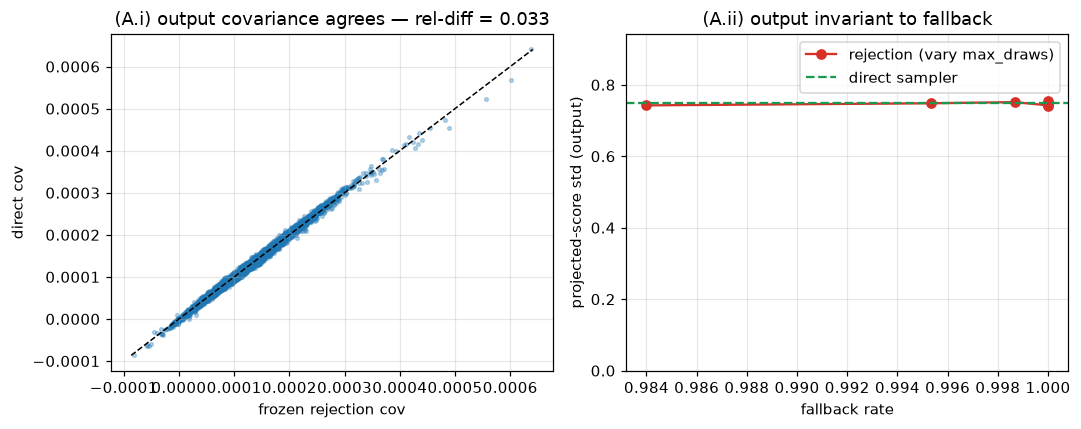

[A] covariance rel-diff 0.033 (<0.08 OK); projected std flat: max/min across fallback 0.98-1.00 = 1.016 (≈1), direct 0.75


In [5]:
src = ph.ArrayBlockSource(VOLS, MASK, block_shape=(5,5,5), N=N, seed=SEED)
pool = src.sample(N, np.random.default_rng(0)).reshape(N,5,5,5)
yv, Dv, Sv = ph.loo_artifacts(pool, ph.pipeline_mean); r = N - 1
fm = me.mech_mode_eigen(yv, Dv, Sv, scale=3.0, k_check=r, max_draws=600, keep_modes=True)
Zf = np.array([fm.sample(np.random.default_rng(1000+i)) for i in range(4000)])
V, lam, bar_l2, _ = R.mode_bundle(Dv.reshape(N,-1), "l2")
Zd = R.draw_coeffs(lam, bar_l2, 3.0, r, 4000, np.random.default_rng(7)) @ V.T
cf, cd = np.cov(Zf.T), np.cov(Zd.T); iu = np.triu_indices(cf.shape[0])
reldiff = np.linalg.norm(cf - cd) / np.linalg.norm(cf)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(cf[iu], cd[iu], s=6, alpha=.3, color="#1f78b4")
lim = [min(cf[iu].min(), cd[iu].min()), max(cf[iu].max(), cd[iu].max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("frozen rejection cov"); ax[0].set_ylabel("direct cov")
ax[0].set_title(f"(A.i) output covariance agrees — rel-diff = {reldiff:.3f}")
dirp = yv.reshape(-1)
fr, sd_out = [], []
for mdw in [1, 2, 4, 8, 20, 60, 200]:
    fmk = me.mech_mode_eigen(yv, Dv, Sv, scale=3.0, k_check=r, max_draws=mdw, keep_modes=True)
    zk = np.array([fmk.sample(np.random.default_rng(i)) for i in range(1500)])
    fr.append(float(getattr(fmk, "fallback_rate", np.nan))); sd_out.append(float((zk @ dirp).std()))
direct_sd = float((R.draw_coeffs(lam, bar_l2, 3.0, r, 4000, np.random.default_rng(9)) @ V.T @ dirp).std())
ax[1].plot(fr, sd_out, "o-", color="#d73027", label="rejection (vary max_draws)")
ax[1].axhline(direct_sd, color="#1a9850", ls="--", label="direct sampler")
ax[1].set_ylim(0, max(max(sd_out), direct_sd)*1.25)      # zero-anchored so flatness is to scale
ax[1].set_xlabel("fallback rate"); ax[1].set_ylabel("projected-score std (output)")
ax[1].set_title("(A.ii) output invariant to fallback"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"[A] covariance rel-diff {reldiff:.3f} (<0.08 OK); projected std flat: "
      f"max/min across fallback {min(fr):.2f}-{max(fr):.2f} = {max(sd_out)/min(sd_out):.3f} (≈1), direct {direct_sd:.3g}")

*Figure 1b-B.* Per-subject coverage CDF. **x:** per-subject coverage fraction = for each subject,
the fraction of policed modes m with `|Dᵢ·Vₘ| ≤ bₘ` (0–1, unitless). **y:** cumulative share of
subjects. **Red:** L2 bar; **green:** per-mode-max. A curve pinned at x = 1 means every subject is
covered in every mode; red sitting left of 1 means those subjects are exposed in some modes.

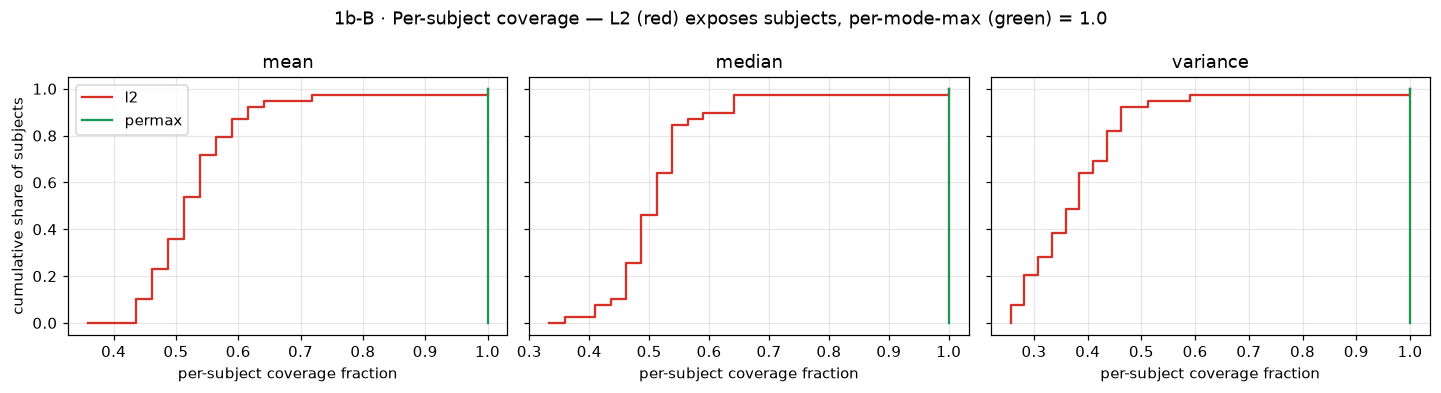

    stat    bar  coverage(mean)  coverage(min subj)
    mean     l2           0.531               0.359
    mean permax           1.000               1.000
  median     l2           0.515               0.333
  median permax           1.000               1.000
variance     l2           0.385               0.256
variance permax           1.000               1.000


In [6]:
fig, axes = plt.subplots(1, len(STATS), figsize=(4.4*len(STATS), 3.6), squeeze=False, sharey=True)
covsum = {}
for a, st in zip(axes[0], STATS):
    sg = R.build_release(COHORT, MASK, st, "single"); proj = sg._proj
    istar = int(np.argmax(np.linalg.norm(proj, axis=1)))
    for bk, col in zip(["l2", "permax"], ["#d73027", "#1a9850"]):
        bar = np.abs(proj).max(0) if bk == "permax" else np.abs(proj[istar])
        per_subj = (np.abs(proj) <= bar[None, :]).mean(1)
        covsum[(st, bk)] = (float(per_subj.mean()), float(per_subj.min()))
        a.plot(np.sort(per_subj), np.linspace(0, 1, N), drawstyle="steps-post", color=col, label=bk)
    a.set_title(st); a.set_xlabel("per-subject coverage fraction")
    if a is axes[0][0]: a.set_ylabel("cumulative share of subjects"); a.legend()
fig.suptitle("1b-B · Per-subject coverage — L2 (red) exposes subjects, per-mode-max (green) = 1.0")
plt.tight_layout(); plt.show()
print(pd.DataFrame([(st, bk, round(m,3), round(mn,3)) for (st, bk), (m, mn) in covsum.items()],
                   columns=["stat","bar","coverage(mean)","coverage(min subj)"]).to_string(index=False))

## 2 · Per-config baseline (at the operating scale)

*Table below.* One row per (patch, overlap): membership advantage for **all three targets** at the
operating scale, with coverage, patch count and the utility panel (rel-MSE, Spearman, SSIM). A sanity
pass before the sweep. advantage ↓ better; rel-MSE ↓ better; Spearman, SSIM ↑ better.

In [7]:
def _baseline(nm, ps, ov):
    st = "mean"; rel_full = R.build_release(COHORT, MASK, st, ps, (0.5 if ov is None else ov), BLEND)
    row = dict(patch=nm, overlap=("-" if ov is None else ov), n_patches=rel_full.n_patches,
               coverage=round(rel_full.coverage()["overall"], 3))
    for tg in TARGETS:
        gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, (0.5 if ov is None else ov), BLEND,
                                          TGT[st][tg], rel_full=(None if tg=="ksigma" else rel_full))
        a = R.advantage_sweep(gi, go, ri, ro, dv, [REP_SCALE], None, N_TRIALS, np.random.default_rng(1))[0]
        row[f"adv_{tg}"] = round(a["advantage"], 3)
    u = R.release_utility(rel_full, REP_SCALE, None, np.random.default_rng(2), n_rel=N_REL)
    row.update(rel_mse=round(u["rel_mse"],4), spearman=round(u["spearman"],3), ssim=round(u["ssim"],3))
    return row
cfgs = [(nm, ps, (None if ps=="single" else ov))
        for nm, ps in PATCHES.items() for ov in (OVERLAPS if ps!="single" else [None])]
BASE = pd.DataFrame(Parallel(**PKW)(delayed(_baseline)(nm, ps, ov) for nm, ps, ov in cfgs))
print(f"baseline @ scale={REP_SCALE}, statistic=mean:"); print(BASE.to_string(index=False))

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   3 out of  10 | elapsed:   54.1s remaining:  2.1min
[Parallel(n_jobs=20)]: Done   5 out of  10 | elapsed:  1.2min remaining:  1.2min
[Parallel(n_jobs=20)]: Done   7 out of  10 | elapsed:  2.2min remaining:   56.9s


baseline @ scale=5, statistic=mean:
 patch overlap  n_patches  coverage  adv_worst  adv_ksigma  adv_istar  rel_mse  spearman  ssim
 3x3x3     0.0       7836       1.0      0.996       0.996      0.999   0.0031     0.978 0.996
 3x3x3    0.25      17896       1.0      0.993       1.000      0.999   0.0031     0.978 0.996
 3x3x3     0.5      17896       1.0      0.993       1.000      0.999   0.0031     0.978 0.996
 5x5x5     0.0       2075       1.0      0.999       1.000      0.998   0.0031     0.978 0.996
 5x5x5    0.25       3314       1.0      0.999       1.000      1.000   0.0031     0.978 0.996
 5x5x5     0.5      17560       1.0      0.999       0.999      0.995   0.0031     0.978 0.996
 7x7x7     0.0        883       1.0      0.999       0.998      0.998   0.0031     0.978 0.996
 7x7x7    0.25       1699       1.0      0.999       1.000      0.998   0.0031     0.978 0.996
 7x7x7     0.5       2543       1.0      1.000       1.000      1.000   0.0031     0.978 0.996
single       -

[Parallel(n_jobs=20)]: Done  10 out of  10 | elapsed:  7.4min finished


## 3 · Frontier sweep — scale × patch{incl. single} × overlap × statistic (k_check = r)

Every config swept over the same scales, same whole-brain projection attack, same utility panel;
modes/bar built once per (patch, overlap, statistic), scale applied at sample time. Cached to
`nb8_ckpt/RES.csv` — delete that folder to recompute. **Note:** a cache produced with two targets is
loaded as-is; plots below adapt to whichever targets are present (add `istar` by recomputing).

In [8]:
t0 = time.time()
CFGS = [(nm, ps, (None if ps=="single" else ov))
        for nm, ps in PATCHES.items() for ov in (OVERLAPS if ps!="single" else [None])]
os.makedirs(CKPT_DIR, exist_ok=True); _ckpt = os.path.join(CKPT_DIR, "RES.csv")
if os.path.exists(_ckpt):
    RES = pd.read_csv(_ckpt)
    print(f"LOADED cached frontier: {_ckpt} ({len(RES)} rows, targets={sorted(RES.target.unique())}, "
          f"scales={sorted(RES.scale.unique())}) -- skipping the sweep.")
else:
    print(f"{len(CFGS)} configs x {len(STATS)} stats = {len(CFGS)*len(STATS)} parallel jobs")
    def _config_job(nm, ps, ov, st):
        ovv = 0.5 if ov is None else ov; rng = np.random.default_rng(hash((nm, ov, st)) % 2**31)
        rel_full = R.build_release(COHORT, MASK, st, ps, ovv, BLEND)
        cov = rel_full.coverage()["overall"]; npat = rel_full.n_patches; ovs = "-" if ov is None else ov
        urows = []
        for sc in SCALES:
            u = R.release_utility(rel_full, sc, None, rng, n_rel=N_REL)
            urows.append(dict(patch=nm, overlap=ovs, stat=st, scale=sc, rel_mse=u["rel_mse"],
                              spearman=u["spearman"], ssim=u["ssim"], nc_gap=u["neighbour_corr_gap"]))
        arows = []
        for target in TARGETS:
            gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, ovv, BLEND, TGT[st][target],
                                              rel_full=(None if target == "ksigma" else rel_full))
            for rw in R.advantage_sweep(gi, go, ri, ro, dv, SCALES, None, N_TRIALS, rng):
                arows.append(dict(patch=nm, overlap=ovs, stat=st, target=target, scale=rw["scale"],
                                  advantage=rw["advantage"], adv_lo=rw["adv_ci"][0],
                                  adv_hi=rw["adv_ci"][1], coverage=cov, n_patches=npat))
        return arows, urows
    jobs = [(nm, ps, ov, st) for (nm, ps, ov) in CFGS for st in STATS]
    out = Parallel(**PKW)(delayed(_config_job)(nm, ps, ov, st) for nm, ps, ov, st in jobs)
    ADV = pd.DataFrame([r for a, _ in out for r in a]); UTL = pd.DataFrame([r for _, u in out for r in u])
    RES = ADV.merge(UTL, on=["patch","overlap","stat","scale"], how="left")
    RES.to_csv(_ckpt, index=False)
    print(f"sweep done in {time.time()-t0:.0f}s | rows: {len(RES)} | cached -> {_ckpt}")
RES["overlap"] = RES["overlap"].astype(str)
TGTS_RES = [t for t in TARGETS if t in set(RES.target)]       # targets actually present in RES
def _ov05(df): return df[df.overlap.astype(str).isin(["-", "0.5"])]

LOADED cached frontier: /indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/nb8_ckpt/RES.csv (360 rows, targets=['ksigma', 'worst'], scales=[np.int64(1), np.int64(2), np.int64(3), np.int64(5), np.int64(8), np.int64(12)]) -- skipping the sweep.


*Figure 3-1.* Membership **advantage vs scale** (log x). **Rows = targets** (worst/ksigma/istar),
**columns = statistics**; one line per patch size (3³/5³/7³ patched at overlap 0.5, plus whole-brain
`single` in red). Dotted line at 0 = chance; shaded band = 95 % CI. Lower is more private.

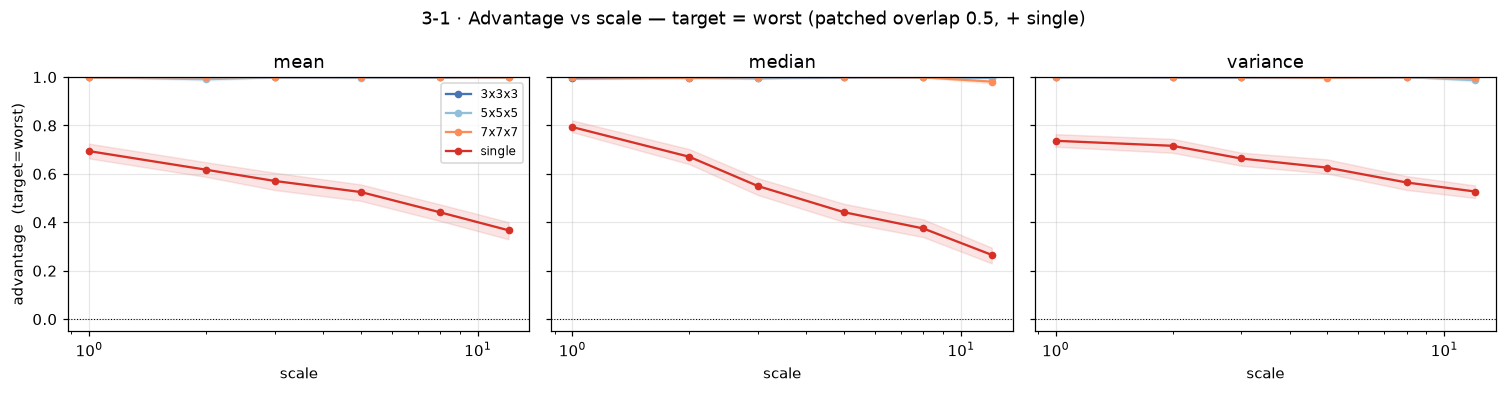

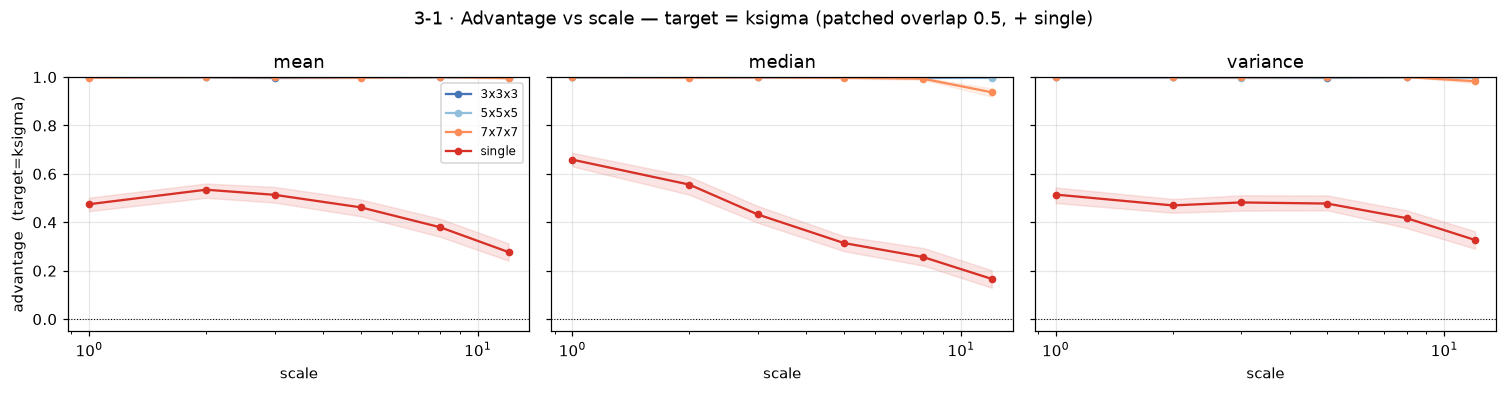

In [9]:
for TG in TGTS_RES:
    fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.6), squeeze=False, sharey=True)
    for a, st in zip(axes[0], STATS):
        sub = _ov05(RES[(RES.stat==st) & (RES.target==TG)])
        for nm in PATCHES:
            s = sub[sub.patch==nm].sort_values("scale")
            if len(s):
                a.plot(s.scale, s.advantage, "o-", color=PCOL.get(nm), label=nm, ms=4)
                a.fill_between(s.scale, s.adv_lo, s.adv_hi, color=PCOL.get(nm), alpha=0.12)
        a.set_title(f"{st}"); a.set_xlabel("scale"); a.set_xscale("log"); a.set_ylim(-0.05, 1.0)
        a.axhline(0.0, color="k", lw=.7, ls=":")
        if a is axes[0][0]: a.set_ylabel(f"advantage  (target={TG})"); a.legend(fontsize=8)
    fig.suptitle(f"3-1 · Advantage vs scale — target = {TG} (patched overlap 0.5, + single)")
    plt.tight_layout(); plt.show()

*Figure 3-2 — overlap vs privacy.* For the patched sizes only (single has no overlap), membership
**advantage (worst target) vs overlap fraction**; **columns = statistics**, one line per patch size, at
the operating scale. Flat high lines ⇒ overlap does not change privacy in this regime.

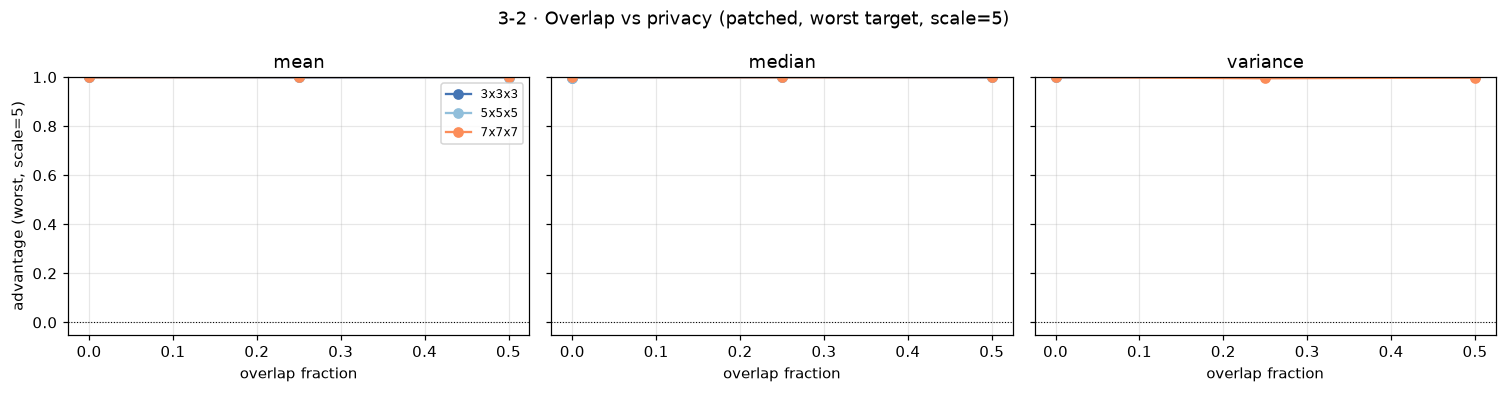

overlap effect (5x5x5, mean, worst) — advantage by scale x overlap:
overlap    0.0   0.25    0.5
scale                       
1        1.000  1.000  1.000
2        0.999  0.999  0.991
3        1.000  0.995  0.999
5        0.999  0.999  0.998
8        0.999  0.999  1.000
12       0.999  0.999  1.000


In [10]:
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.6), squeeze=False, sharey=True)
for a, st in zip(axes[0], STATS):
    sub = RES[(RES.stat==st) & (RES.target=="worst") & (RES.scale==REP_SCALE) & (RES.patch!="single")]
    for nm in [p for p in PATCHES if p != "single"]:
        s = sub[sub.patch==nm].copy()
        if len(s):
            s["ov"] = s.overlap.astype(float); s = s.sort_values("ov")
            a.plot(s.ov, s.advantage, "o-", color=PCOL.get(nm), label=nm)
    a.set_title(st); a.set_xlabel("overlap fraction"); a.set_ylim(-0.05, 1.0)
    a.axhline(0.0, color="k", lw=.7, ls=":")
    if a is axes[0][0]: a.set_ylabel(f"advantage (worst, scale={REP_SCALE})"); a.legend(fontsize=8)
fig.suptitle(f"3-2 · Overlap vs privacy (patched, worst target, scale={REP_SCALE})")
plt.tight_layout(); plt.show()
print("overlap effect (5x5x5, mean, worst) — advantage by scale x overlap:")
print(RES[(RES.patch==REP_PATCH)&(RES.stat=="mean")&(RES.target=="worst")]
      .pivot_table(index="scale", columns="overlap", values="advantage").round(3).to_string())

## 3b · k_check (policing depth) → privacy and utility

Sweep the number of policed modes `k_check` ∈ {8, 16, 26, r} (r = full rank). Run on the
whole-brain **single** release (where advantage is in an informative range) **and** 5³ (saturated
reference), all targets, at a low and a high scale. Hypothesis: advantage **rises** as `k_check` falls
(tail modes left with only natural noise), at **lower** distortion — the test of whether full-rank
policing earns its cost. Both privacy and utility are measured vs `k_check`.

In [11]:
KC_PATCHES = [("single","single"), (REP_PATCH, PATCHES[REP_PATCH])]
def _kc_job(pname, ps, st):
    ovv = 0.5; rel_full = R.build_release(COHORT, MASK, st, ps, ovv, BLEND)
    urows = []
    for sc in KC_SCALES:
        for kc in KCHECKS:
            u = R.release_utility(rel_full, sc, kc, np.random.default_rng(5), n_rel=N_REL)
            urows.append(dict(patch=pname, stat=st, scale=sc, k_check=("r" if kc is None else str(kc)),
                              rel_mse=u["rel_mse"], spearman=u["spearman"]))
    arows = []
    for target in TARGETS:
        gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, ovv, BLEND, TGT[st][target],
                                          rel_full=(None if target=="ksigma" else rel_full))
        for sc in KC_SCALES:
            for rw in R.kcheck_sweep(gi, go, ri, ro, dv, sc, KCHECKS, N_TRIALS, np.random.default_rng(3)):
                arows.append(dict(patch=pname, stat=st, target=target, scale=sc,
                                  k_check=("r" if rw["k_check"] is None else str(rw["k_check"])),
                                  advantage=rw["advantage"]))
    return arows, urows
_kcjobs = [(pn, ps, st) for (pn, ps) in KC_PATCHES for st in STATS]
_out = Parallel(**PKW)(delayed(_kc_job)(pn, ps, st) for pn, ps, st in _kcjobs)
KC  = pd.DataFrame([r for a,_ in _out for r in a]); KCU = pd.DataFrame([r for _,u in _out for r in u])
kc_order = [("r" if k is None else str(k)) for k in KCHECKS]

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   2 out of   6 | elapsed:  1.5min remaining:  3.0min
[Parallel(n_jobs=20)]: Done   3 out of   6 | elapsed:  2.1min remaining:  2.1min
[Parallel(n_jobs=20)]: Done   4 out of   6 | elapsed: 34.8min remaining: 17.4min
[Parallel(n_jobs=20)]: Done   6 out of   6 | elapsed: 39.0min finished


*Figure 3b-1 — privacy vs k_check.* At the **low** scale (where policing matters most),
**rows = patch** (single, 5³), **columns = statistic**; one line per target. x = k_check (8 → r).
A rising-to-the-left curve supports "fewer policed modes ⇒ more leakage". 5³ is expected flat-high
(saturated); single is the informative row.

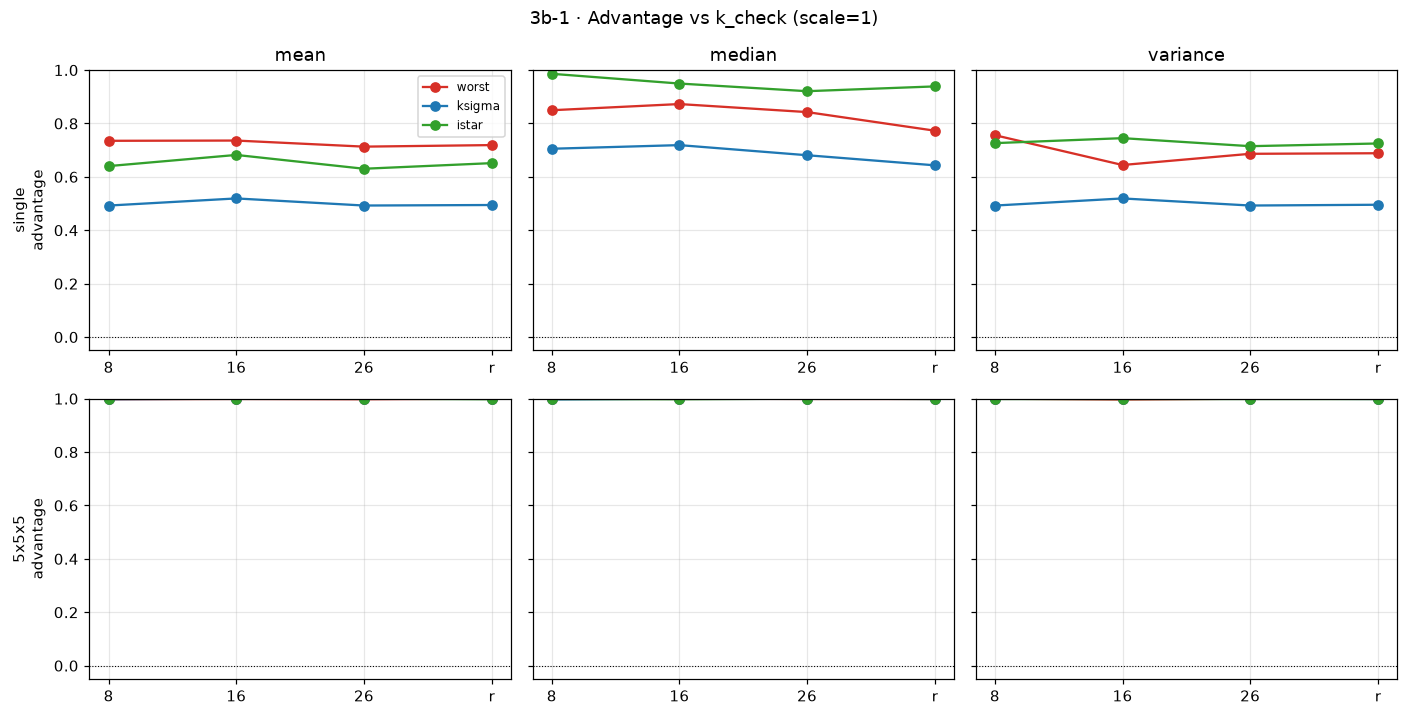

k_check                     8     16     26      r
patch  stat     target                            
5x5x5  mean     istar   1.000  1.000  1.000  0.998
                ksigma  0.998  1.000  1.000  1.000
                worst   0.998  0.999  0.998  1.000
       median   istar   0.999  0.998  1.000  0.999
                ksigma  0.997  1.000  1.000  0.999
                worst   1.000  1.000  0.999  0.999
       variance istar   1.000  1.000  1.000  1.000
                ksigma  1.000  1.000  1.000  0.999
                worst   1.000  0.997  1.000  1.000
single mean     istar   0.640  0.682  0.630  0.651
                ksigma  0.493  0.519  0.493  0.495
                worst   0.735  0.736  0.713  0.719
       median   istar   0.986  0.950  0.921  0.939
                ksigma  0.705  0.719  0.681  0.643
                worst   0.850  0.873  0.843  0.773
       variance istar   0.726  0.745  0.715  0.725
                ksigma  0.493  0.519  0.493  0.496
                worst   0.756  

In [12]:
LOW = KC_SCALES[0]
fig, axes = plt.subplots(len(KC_PATCHES), len(STATS), figsize=(4.3*len(STATS), 3.3*len(KC_PATCHES)),
                         squeeze=False, sharey=True)
for i,(pn,_) in enumerate(KC_PATCHES):
    for j, st in enumerate(STATS):
        a = axes[i][j]
        for tg in TARGETS:
            s = KC[(KC.patch==pn)&(KC.stat==st)&(KC.target==tg)&(KC.scale==LOW)].set_index("k_check")
            s = s.reindex([k for k in kc_order if k in s.index])
            a.plot(range(len(s)), s.advantage, "o-", color=TCOL[tg], label=tg)
        a.set_xticks(range(len(kc_order))); a.set_xticklabels(kc_order)
        a.set_ylim(-0.05,1.0); a.axhline(0,color="k",lw=.7,ls=":")
        if i==0: a.set_title(st)
        if j==0: a.set_ylabel(f"{pn}\nadvantage")
        if i==0 and j==0: a.legend(fontsize=8)
fig.suptitle(f"3b-1 · Advantage vs k_check (scale={LOW})"); plt.tight_layout(); plt.show()
print(KC[KC.scale==LOW].pivot_table(index=["patch","stat","target"], columns="k_check",
      values="advantage").reindex(columns=kc_order).round(3).to_string())

*Figure 3b-2 — utility vs k_check.* rel-MSE (↓ better) vs k_check at the low scale, one line per
patch, column per statistic. More policed modes (toward r) should cost more distortion; read against
3b-1 to see whether the privacy gain is worth the utility cost.

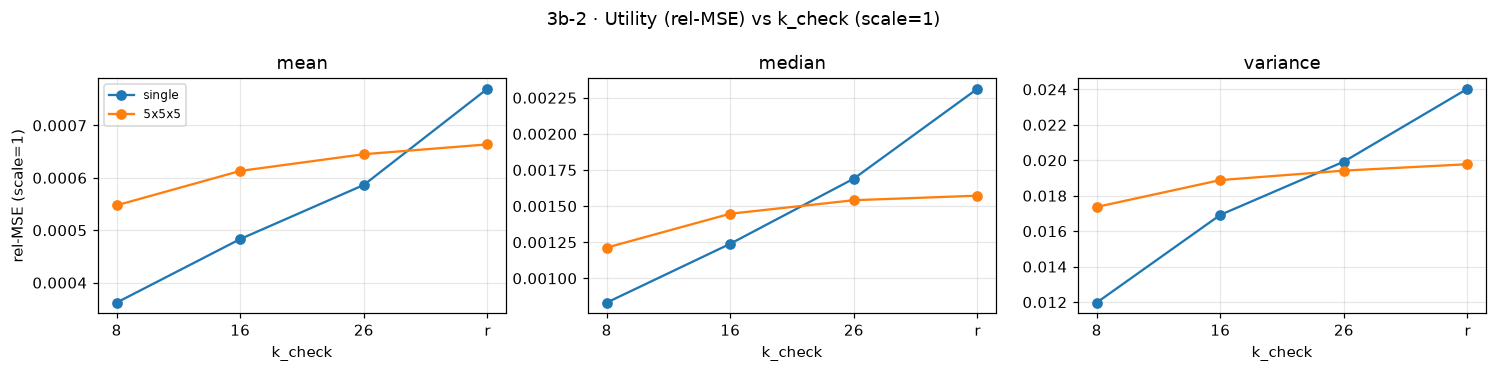

In [13]:
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.4), squeeze=False, sharey=False)
for a, st in zip(axes[0], STATS):
    for pn,_ in KC_PATCHES:
        s = KCU[(KCU.patch==pn)&(KCU.stat==st)&(KCU.scale==LOW)].set_index("k_check")
        s = s.reindex([k for k in kc_order if k in s.index])
        a.plot(range(len(s)), s.rel_mse, "o-", label=pn)
    a.set_xticks(range(len(kc_order))); a.set_xticklabels(kc_order)
    a.set_title(st); a.set_xlabel("k_check")
    if a is axes[0][0]: a.set_ylabel(f"rel-MSE (scale={LOW})"); a.legend(fontsize=8)
fig.suptitle(f"3b-2 · Utility (rel-MSE) vs k_check (scale={LOW})"); plt.tight_layout(); plt.show()

## 3c · N-subject influence

*Figure 3c.* Membership **advantage (worst target) vs cohort size N**, at the operating scale, for
the whole-brain **single** release and 5³. x = N; one line per (patch, statistic). Prediction: roughly
flat with N (the bar scales with each subject's influence, so dilution cancels) — N buys privacy only
through rank/aggregation, which plateaus. Dotted line = chance.

In [ ]:
def _n_job(n, pname, ps, st, target):
    coh = VOLS[:n]; tgt = R.select_targets(coh, MASK, st)[target]
    gi, go, ri, ro, dv = R.two_worlds(coh, MASK, st, ps, 0.5, BLEND, tgt)
    adv = R.advantage_sweep(gi, go, ri, ro, dv, [REP_SCALE], None, N_TRIALS,
                            np.random.default_rng(4))[0]["advantage"]
    return dict(N=n, patch=pname, stat=st, target=target, advantage=adv)
_njobs = [(n, pn, ps, st, tg) for n in N_SWEEP for (pn, ps) in KC_PATCHES for st in STATS for tg in TARGETS]
NS = pd.DataFrame(Parallel(**PKW)(delayed(_n_job)(n, pn, ps, st, tg) for n, pn, ps, st, tg in _njobs))
fig, ax = plt.subplots(figsize=(7, 4.2))
for pn,_ in KC_PATCHES:
    for st in STATS:
        s = NS[(NS.patch==pn)&(NS.stat==st)&(NS.target=="worst")].sort_values("N")
        ax.plot(s.N, s.advantage, "o-" if pn=="single" else "s--", label=f"{pn}·{st}")
ax.set_xlabel("N (cohort size)"); ax.set_ylabel("advantage (worst)"); ax.set_ylim(-0.05, 1.0)
ax.axhline(0.0, color="k", lw=.7, ls=":"); ax.set_title(f"3c · Advantage vs N (scale={REP_SCALE})")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
print(NS[NS.target=="worst"].pivot_table(index="N", columns=["patch","stat"], values="advantage").round(3).to_string())

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:    4.5s
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:   18.2s
[Parallel(n_jobs=20)]: Done  21 tasks      | elapsed:  1.3min
[Parallel(n_jobs=20)]: Done  32 tasks      | elapsed:  2.5min
/indirect/student/lukasschuler/test/wp15/infrastructure/privacy_dev/DP/lib64/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


## 4 · Reconstruction + outlier-detectability (mean release)

For the identifiable **mean** release the attacker inverts the group mean: `x̂ = N·R − Σbg =
target + N·z`. Run for **all three targets**. Because the released per-subject-sized noise is multiplied
by N in the inversion, the reconstruction is swamped by noise — so the outlier *flag* saturates and the
**reconstruction error** `‖x̂ − target‖ / ‖target‖` (↑ with scale = more protection) is the meaningful
readout; the membership advantage (§3) is the sharper privacy measure.

*Figure 4.* **Left:** reconstruction error vs scale, one line per target (↑ = better protected).
**Right:** private outlier-flag rate vs scale (saturates at 1 due to the ×N amplification — shown for
transparency). Table beneath gives the raw numbers.

In [ ]:
mb = MASK.reshape(-1); relS = R.build_release(COHORT, MASK, "mean", "single")
def _tgt_vox(tg):
    if tg == "ksigma": return TGT["mean"]["ksigma"].reshape(-1)[mb], COHORT.reshape(N,-1)[1:, mb]
    i = TGT["mean"][tg]; v = COHORT.reshape(N,-1)[:, mb]
    return v[i], np.delete(v, i, 0)
rows = []
for tg in TARGETS:
    tvox, bg = _tgt_vox(tg)
    for sc in SCALES:
        nmdl = R.fixed_noise(relS, sc, None)
        od = fra.outlier_detectability(bg, tvox, N, nmdl, np.random.default_rng(5), n_rel=min(200,4*N_REL))
        errs = [np.linalg.norm(tvox + N*nmdl.sample(np.random.default_rng(k)) - tvox)/(np.linalg.norm(tvox)+1e-12)
                for k in range(min(200,4*N_REL))]
        rows.append(dict(target=tg, scale=sc, clean_z_flag=od["clean_z_flag"],
                         private_z_rate=round(od["private_z_rate"],3), recon_err=round(float(np.mean(errs)),3)))
    print(f"  target {tg} done")
REC = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for tg in TARGETS:
    s = REC[REC.target==tg].sort_values("scale")
    ax[0].plot(s.scale, s.recon_err, "o-", color=TCOL[tg], label=tg)
    ax[1].plot(s.scale, s.private_z_rate, "o-", color=TCOL[tg], label=tg)
ax[0].set_xlabel("scale"); ax[0].set_ylabel("reconstruction error ‖x̂−t‖/‖t‖ (↑ better)"); ax[0].legend()
ax[1].set_xlabel("scale"); ax[1].set_ylabel("private outlier-flag rate"); ax[1].set_ylim(-0.05,1.05); ax[1].legend()
fig.suptitle("4 · Reconstruction error & outlier-flag rate vs scale (mean release)")
plt.tight_layout(); plt.show()
print(REC.pivot_table(index="scale", columns="target", values=["recon_err","private_z_rate"]).to_string())

## 5 · Inference validity on the imaging release (mass-univariate, corrected)

Per-voxel one-sample t-test on the released mean map. Null = sign-flip permutation of the centered
cohort deviations (true per-voxel mean 0) → clean corrected FWER ≈ α; the mechanism noise is added to
the mean map and the test re-run → private FWER = Type-1 inflation. A fixed regional effect gives power.
Bonferroni (FWER) and Benjamini–Hochberg (FDR).

*Figure 5.* Corrected **FWER (null) vs scale**, one line per config; the hard bar is expected to
inflate Type-1 as scale rises. Clean FWER (scale 0) should sit near α = 0.05 (dotted).

In [ ]:
inf_cfgs = [("single", "single", None)] + ([("5x5x5", (5,5,5), 0.5)] if "5x5x5" in PATCHES else [])
inf_scales = sorted({0.0, float(SCALES[0]), float(REP_SCALE), float(SCALES[-1])})
def _inf_job(nm, ps, ov, sc, mode):
    relm = R.build_release(COHORT, MASK, "mean", ps, (0.5 if ov is None else ov), BLEND)
    o = R.imaging_inference(relm, COHORT, MASK, sc, None, alpha=0.05, n_mc=N_MC, effect=0.8,
                            region_frac=0.05, seed=SEED, mode=mode)
    return dict(config=nm, mech=mode, scale=sc, FWER_clean=round(o["fwer_clean"],3),
                FWER_priv=round(o["fwer_priv"],3), BHfp_priv=round(o["fdr_fp_priv"],3),
                pow_clean=round(o["pow_bh_clean"],3), pow_priv=round(o["pow_bh_priv"],3))
_ijobs = [(nm, ps, ov, sc, "hardbar") for (nm, ps, ov) in inf_cfgs for sc in inf_scales]
INF = pd.DataFrame(Parallel(**PKW)(delayed(_inf_job)(*j) for j in _ijobs)).sort_values(["config","scale"])
print("hard bar — clean FWER ~ alpha, private FWER = Type-1 inflation:"); print(INF.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.6, 4))
for nm in INF.config.unique():
    s = INF[INF.config==nm].sort_values("scale"); ax.plot(s.scale, s.FWER_priv, "o-", label=f"{nm}")
ax.axhline(0.05, color="k", ls=":", label="α = 0.05"); ax.set_xlabel("scale"); ax.set_ylabel("corrected FWER (null)")
ax.set_title("5 · Type-1 inflation on the imaging release (hard bar)"); ax.legend(); plt.tight_layout(); plt.show()

### 5b · Option B (variance-inflation) — the inference-friendlier alternative

**Option B restated:** instead of forcing `|aₘ| ≥ bₘ` every draw (the hard bar, non-Gaussian), each
mode is plain Gaussian `aₘ ~ N(0, σₘ²)` with `σₘ² = max(scale²·λₘ, bₘ²)` — it covers the bar *in
expectation*, not per draw, so the noise stays Gaussian. Hypothesis: Option B keeps Type-1 near nominal
while the hard bar inflates it. Below: the **same** inference experiment, same configs/scales, hard bar
vs Option B, so the effect is directly comparable.

*Figure 5b.* Corrected FWER (null) vs scale; **solid = hard bar, dashed = Option B**, one colour
per config. Option B staying near α while hard bar climbs would confirm the inference advantage of the
Gaussian variant.

In [ ]:
_ijobs2 = [(nm, ps, ov, sc, "optB") for (nm, ps, ov) in inf_cfgs for sc in inf_scales]
INFB = pd.DataFrame(Parallel(**PKW)(delayed(_inf_job)(*j) for j in _ijobs2)).sort_values(["config","scale"])
BOTH = pd.concat([INF, INFB], ignore_index=True)
print("hard bar vs Option B (FWER_priv / power), matched conditions:")
print(BOTH.pivot_table(index=["config","scale"], columns="mech",
      values=["FWER_priv","pow_priv"]).round(3).to_string())
fig, ax = plt.subplots(figsize=(6.8, 4)); ccol = {c:col for c,col in zip(INF.config.unique(), ["#d73027","#1f78b4"])}
for nm in BOTH.config.unique():
    for mech, ls in [("hardbar","o-"), ("optB","s--")]:
        s = BOTH[(BOTH.config==nm)&(BOTH.mech==mech)].sort_values("scale")
        ax.plot(s.scale, s.FWER_priv, ls, color=ccol.get(nm,"k"), label=f"{nm}·{mech}")
ax.axhline(0.05, color="k", ls=":", label="α = 0.05"); ax.set_xlabel("scale"); ax.set_ylabel("corrected FWER (null)")
ax.set_title("5b · Hard bar vs Option B — Type-1 on the imaging release"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6 · Frontier, utility panel, and configuration selection

*Figure 6.* Privacy–utility frontier: **advantage (x, ↓ better) vs rel-MSE (y, log, ↓ better)**,
one marker per scale connected per patch; **rows = targets**, **columns = statistics**; lower-left is
better. Single in red.

In [ ]:
for TG in TGTS_RES:
    fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.8), squeeze=False)
    for a, st in zip(axes[0], STATS):
        sub = _ov05(RES[(RES.stat==st) & (RES.target==TG)])
        for nm in PATCHES:
            s = sub[sub.patch==nm].sort_values("scale")
            if len(s): a.plot(s.advantage, s.rel_mse, "o-", color=PCOL.get(nm), label=nm, ms=4)
        a.set_title(st); a.set_xlabel("advantage (↓)"); a.set_yscale("log"); a.axvline(EPS,color="k",lw=.7,ls=":")
        if a is axes[0][0]: a.set_ylabel(f"rel-MSE (↓)  [target={TG}]"); a.legend(fontsize=8)
    fig.suptitle(f"6 · Privacy–utility frontier — target={TG} (vertical line = ε={EPS})")
    plt.tight_layout(); plt.show()

**Utility panel** at the operating scale (single vs the overlap-0.5 patched sizes), all metrics
used in the project. rel-MSE ↓ better; neighbour-corr gap ↓ better (spatial smoothness preserved);
Spearman ↑ better (rank preserved); SSIM ↑ better (structural similarity) — NaN if scikit-image absent.

In [ ]:
pan = _ov05(RES[(RES.stat=="mean") & (RES.target=="worst") & (RES.scale==REP_SCALE)])
cols = ["patch","overlap","n_patches","rel_mse","nc_gap","spearman","ssim"]
print(f"utility panel @ scale={REP_SCALE}, mean:   (rel_mse↓ nc_gap↓ spearman↑ ssim↑)")
print(pan[cols].sort_values("n_patches").round(4).to_string(index=False))

### Configuration selection

**Objective:** minimise membership advantage subject to utility, at least computational cost.
**Criterion:** a config is *acceptable* when the **upper 95 % CI of advantage ≤ ε = 0.1** for the worst
target at some tested scale. **Cost** proxy: number of patch builds (`n_patches`).

In [ ]:
print(f"smallest scale with adv_hi <= {EPS} (worst target), per config (overlap 0.5 / single):")
sel = _ov05(RES[RES.target=="worst"])
recs = []
for (nm, st), g in sel.groupby(["patch","stat"]):
    ok = g[g.adv_hi <= EPS].sort_values("scale")
    npat = int(g.n_patches.iloc[0])
    if len(ok):
        b = ok.iloc[0]; recs.append(dict(patch=nm, stat=st, meets=True, scale=int(b.scale),
                                         adv_hi=round(b.adv_hi,3), rel_mse=round(b.rel_mse,4), n_patches=npat))
    else:
        b = g.sort_values("scale").iloc[-1]
        recs.append(dict(patch=nm, stat=st, meets=False, scale=f">{int(b.scale)}",
                         adv_hi=round(b.adv_hi,3), rel_mse=round(b.rel_mse,4), n_patches=npat))
SELE = pd.DataFrame(recs).sort_values(["stat","n_patches"])
print(SELE.to_string(index=False))
meets = SELE[SELE.meets]
if len(meets):
    cheap = meets.sort_values(["stat","n_patches"]).groupby("stat").first()
    print("\nconfigs meeting the criterion, cheapest per statistic:"); print(cheap.to_string())
else:
    print(f"\nNO tested config reaches adv_hi <= {EPS} within scale {max(SCALES)}. "
          f"Cheapest + most private is `single` (n_patches=1); it needs scale beyond the tested range "
          f"for mean/variance. Recommendation: `single` + a higher scale; see the frontier for the trade-off.")

## 9 · Isolated-patch baselines (leakage before assembly)

Does a **single isolated patch** release leak before any tiling/blending? Release ONE patch of
size {3³,5³,7³} centred on the worst target's peak-|Δ| voxel, with no assembly, and run the same
projection attack. Compare to (i) the **assembled** tiled release of the same patch size (from §3,
overlap 0.5) and (ii) the whole-brain **single** release. This separates per-patch leakage from any
amplification introduced by overlap/blending.

*Figure 9.* Membership **advantage (worst, mean) vs scale**. **Solid** = isolated single patch;
**dashed** = assembled tiled release of the same size (from §3); red = whole-brain single. If isolated
patches already leak, privacy loss is intrinsic to the patch statistic, not to assembly.

In [ ]:
st = "mean"; tgt = TGT[st]["worst"]
center = R.peak_influence_voxel(COHORT, MASK, st, tgt)
iso_rows = []
def _iso_job(psz):
    gi, go, ri, ro, dv, npx = R.isolated_patch_worlds(COHORT, MASK, st, psz, center, tgt)
    out = []
    for rw in R.advantage_sweep(gi, go, ri, ro, dv, SCALES, None, N_TRIALS, np.random.default_rng(9)):
        out.append(dict(size=f"{psz[0]}x{psz[1]}x{psz[2]}", npx=npx, scale=rw["scale"], advantage=rw["advantage"]))
    return out
ISO = pd.DataFrame([r for rows in Parallel(**PKW)(delayed(_iso_job)(p) for p in ISO_SIZES) for r in rows])
fig, ax = plt.subplots(figsize=(7, 4.2))
for psz in ISO_SIZES:
    key = f"{psz[0]}x{psz[1]}x{psz[2]}"; s = ISO[ISO["size"]==key].sort_values("scale")
    ax.plot(s.scale, s.advantage, "o-", color=PCOL.get(key), label=f"isolated {key}")
    asm = _ov05(RES[(RES.stat==st)&(RES.target=="worst")&(RES.patch==key)]).sort_values("scale")
    if len(asm): ax.plot(asm.scale, asm.advantage, "s--", color=PCOL.get(key), alpha=.7, label=f"assembled {key}")
sgl = RES[(RES.stat==st)&(RES.target=="worst")&(RES.patch=="single")].sort_values("scale")
if len(sgl): ax.plot(sgl.scale, sgl.advantage, "^-", color=PCOL["single"], label="whole-brain single")
ax.set_xscale("log"); ax.set_xlabel("scale"); ax.set_ylabel("advantage (worst, mean)"); ax.set_ylim(-0.05,1.0)
ax.axhline(0,color="k",lw=.7,ls=":"); ax.set_title(f"9 · Isolated vs assembled patch release (center {center})")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(ISO.pivot_table(index="scale", columns="size", values="advantage").round(3).to_string())

## Summary (reads from the run — no hard-coded conclusions)

Interpret the figures together:
- **Frontier (§3, §6):** compare where each patch size and `single` sit; the operating scale per
  statistic and the acceptable configs come from the §6 selection table (criterion adv_hi ≤ ε).
- **Overlap (§3-2):** whether overlap moves advantage at all in the tested regime.
- **k_check (§3b):** whether advantage rises as policing depth falls, and at what utility cost — the
  justification (or not) for `k_check = r`.
- **N (§3c):** whether more subjects buy privacy (prediction: roughly flat).
- **Reconstruction (§4):** reconstruction error growth vs scale, per target.
- **Inference (§5 / 5b):** hard-bar Type-1 inflation vs Option B's near-nominal FWER — the mechanism
  trade-off for the supervisor.
- **Isolated patches (§9):** whether leakage exists per-patch before assembly.

The residual aggregation leak (advantage stays appreciable at the operating scale) is structural; a
composition-aware / formal-DP calibration is the fix, out of scope here.